# PFSS features for the linear model (current-sheet distance kept)

**The question:** do coronal magnetic-field features from a potential-field source-surface (PFSS)
model improve the submitted linear model on the official metric? From `docs/model_review.md` §3.1:
Bailey et al. 2021 rank the flux-tube expansion factor and the distance to the coronal-hole
boundary as the most decisive WSA inputs.

- **Maps:** GONG zero-point-corrected hourly synoptic maps (`mrzqs`), one solved per 12 h, the newest posted by t0 − 10 min and observed within 72 h (`training.pull_gong`).
- **Solver:** sunkit-magex (the pfsspy successor), nr = 35, rss = 2.5 R☉; field lines traced from a 360-longitude ring on the source surface at the sub-Earth latitude (`feature_engineering.pfss`).
- **Windows:** each ring signal read at the Carrington longitude that faced Earth L hours before t0; `_lead_72h` uses, for lead k, the longitude facing Earth about 72 h before t0 + k.
- **Rule, set before running:** keep only if > 1% better than the submitted config and winning ≥ 4 of 6 yearly folds.

Study: `python -m training.pfss_features`; results `src/experiments/pfss_features.csv`; write-up `docs/pfss.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import pfss_features as pf

df = pd.read_csv(pf.EXPERIMENTS / "pfss_features.csv").set_index("variant")
years = [c.split()[1] for c in df.columns if c.startswith("ratio ")]
ratios = df[[f"ratio {y}" for y in years]]
ratios.columns = years
rel = ratios / ratios.loc["shipped"]
summary = pd.DataFrame({
    "/ persistence": df["objective"],
    "vs shipped %": 100 * (np.exp(np.log(rel).mean(axis=1)) - 1),
    "folds won": (rel < 1).sum(axis=1),
}).sort_values("/ persistence")
summary["keep"] = ((summary["vs shipped %"] < -100 * pf.KEEP_GAIN)
                   & (summary["folds won"] >= pf.KEEP_FOLDS))
summary.round(4)

,/ persistence,vs shipped %,folds won,keep
variant,,,,
pfss_d_hcs_lead_72h + pfss_log_fs_lead_48h,0.7778,-1.8602,6,True
pfss_d_hcs_lead_72h + pfss_log_fs_lead_48h + pfss_hcs_max_lat_at_0h,0.7787,-1.7474,5,True
+ pfss_d_hcs_lead_72h,0.7794,-1.6631,5,True
+ pfss_d_hcs_lead_48h,0.7805,-1.5218,5,True
+ pfss_d_hcs_lead_24h,0.7845,-1.0132,4,True
+ pfss_d_hcs_lead_96h,0.7856,-0.8762,4,False
+ pfss_log_fs_lead_48h,0.7882,-0.5472,3,False
+ pfss_log_fs_lead_72h,0.7890,-0.4443,3,False
+ pfss_log_fs_lead_96h,0.7898,-0.3523,6,False


## 1. Every variant against the submitted config

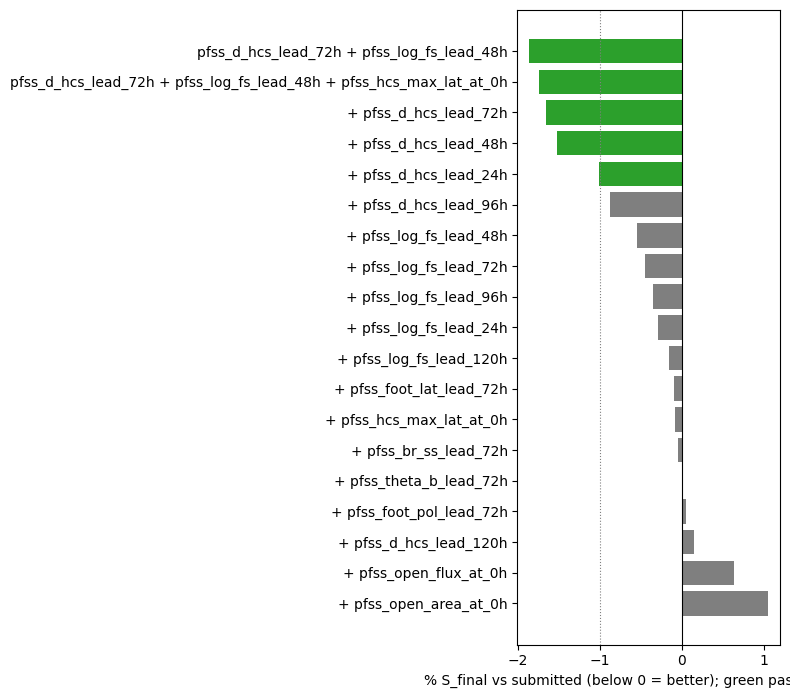

In [2]:
s = summary.drop("shipped")
fig, ax = plt.subplots(figsize=(8, 0.32 * len(s) + 1))
ax.barh(s.index, s["vs shipped %"], color=["C2" if k else "C7" for k in s["keep"]])
ax.axvline(0, color="k", lw=.8)
ax.axvline(-100 * pf.KEEP_GAIN, color="grey", ls=":", lw=.8)
ax.invert_yaxis()
ax.set_xlabel("% S_final vs submitted (below 0 = better); green passes the rule")
plt.tight_layout()

Only the current-sheet distance (`d_hcs`) passes, at delays of 24–72 h. The expansion factor
helps a little (−0.3 to −0.6%) without passing; the coronal-hole boundary distance, footpoint
latitude and polarity, and the map scalars add nothing or hurt. The pair with the expansion factor
is 0.2% better than `d_hcs` alone, well under the 1% a feature has to earn, so `d_hcs` at 72 h
ships alone.

## 2. By fold

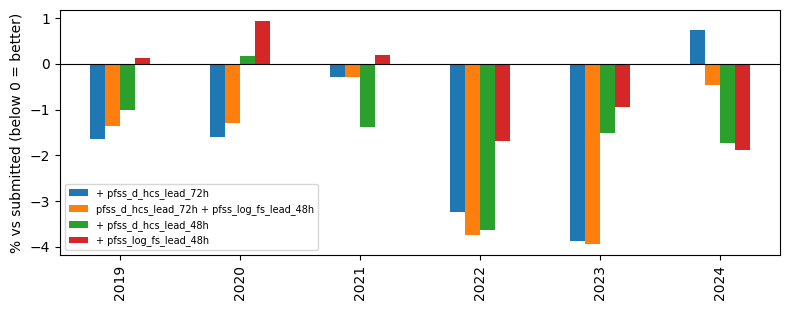

In [3]:
best = ["+ pfss_d_hcs_lead_72h", "pfss_d_hcs_lead_72h + pfss_log_fs_lead_48h",
        "+ pfss_d_hcs_lead_48h", "+ pfss_log_fs_lead_48h"]
ax = (100 * (rel.loc[best].T - 1)).plot.bar(figsize=(8, 3.2))
ax.axhline(0, color="k", lw=.8)
ax.set_ylabel("% vs submitted (below 0 = better)")
ax.legend(fontsize=7)
plt.tight_layout()

## 3. Coverage of the ring history

2016    1.000
2017    0.995
2018    0.925
2019    0.663
2020    0.813
2021    0.884
2022    0.878
2023    0.968
2024    1.000
2025    0.999
2026    0.945


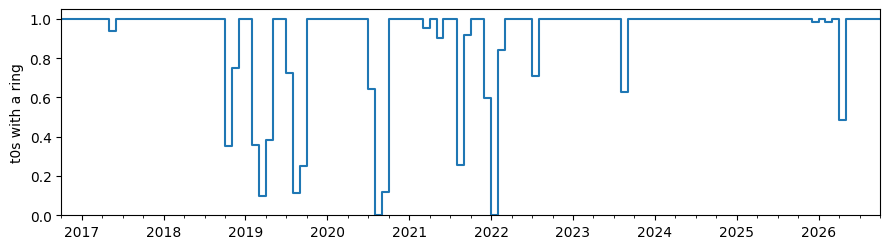

In [4]:
from training import pull_gong

rings = pull_gong.load_ring_table()
has = pd.Series(np.isfinite(rings.ring).any(axis=(1, 2)), index=rings.t0)
cov = has.resample("MS").mean()
ax = cov.plot(figsize=(9, 2.6), drawstyle="steps-post")
ax.set_ylabel("t0s with a ring")
ax.set_ylim(0, 1.05)
plt.tight_layout()
print(has.groupby(has.index.year).mean().round(3).to_string())

The gaps (2019, 2020-08, 2022-01 and others) are maps that were never posted on time: 383
days of 2018–2022 were bulk-backfilled later, and a live run would not have had them, so they
are excluded. Coverage matches the inventory exactly, so no solve failed.

## 4. What the feature measures

,count,25%,50%,75%
d_hcs,,,,
"(0, 5]",2175.0,341.0,378.0,428.0
"(5, 10]",1868.0,344.0,385.0,432.0
"(10, 15]",1654.0,357.0,391.0,454.0
"(15, 20]",1294.0,357.0,407.0,478.0
"(20, 30]",1502.0,362.0,420.0,506.0
"(30, 45]",1277.0,389.0,460.0,554.0
"(45, 90]",825.0,403.0,480.0,551.0


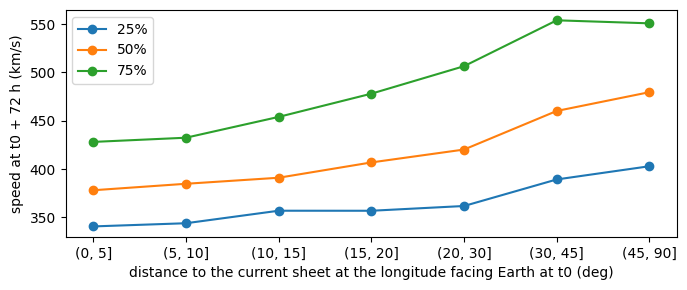

In [5]:
from training import linear_model as tl
from training.datasets import load_train

series = load_train()
t0s = tl.training_runs(series)
d = pf.pfss_table(t0s)["pfss_d_hcs_at_0h"]
v72 = series.reindex(t0s + pd.Timedelta(hours=72)).to_numpy()
frame = pd.DataFrame({"d_hcs": d.to_numpy(), "v72": v72}).dropna()
bins = pd.cut(frame["d_hcs"], [0, 5, 10, 15, 20, 30, 45, 90])
g = frame.groupby(bins, observed=True)["v72"].describe()[["count", "25%", "50%", "75%"]]
ax = g[["25%", "50%", "75%"]].plot(marker="o", figsize=(7, 3))
ax.set_xlabel("distance to the current sheet at the longitude facing Earth at t0 (deg)")
ax.set_ylabel("speed at t0 + 72 h (km/s)")
plt.tight_layout()
g.round(0)

Wind from far from the current sheet is faster: the median speed 72 h later rises from slow
wind near the sheet to fast wind 30° or more away. That is the slow-wind / sector-boundary picture
the feature was expected to carry, and it is information the speed history and the coronal-hole
strip don't fully have.